![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 2.0. Coupler Design

## 0. Imports 

### 0.1. General libraries

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import tidy3d as td
import gplugins.tidy3d as gt

nm = 1e-3
wavelength = np.linspace(1500, 1600) * nm
f = td.C_0 / wavelength


### 0.2. Functions by us

In [3]:
from upvfab_design_tools import MMI_EME, DC_EME

In [4]:
nitride_complex = td.material_library["Si3N4"]["Luke2015PMLStable"].eps_model(f)
nitride_index, nitride_k = td.Medium.eps_complex_to_nk(nitride_complex)
box_complex = td.material_library["SiO2"]["Horiba"].eps_model(f)
box_index, box_k = td.Medium.eps_complex_to_nk(box_complex)

## LO.1. Directional coupler length and coupling coefficient

The total power transferred to the output is modeled using the coupling coefficient (K). This coefficient depends on the relationship between the physical length of the coupling region and the beating length:

<img src="k.png" alt="Coupling Coefficient Equation" width="400">

Simulate a directional coupler that implements two deep waveguide cores of 1.2 microns width and with a gap of 600 nm between them. 
- Plot the transfer function: K vs L/Lpi
- Comment the results: distance needed for a complete energy transfer between waveguides, distance needed for splitting power in half.. 

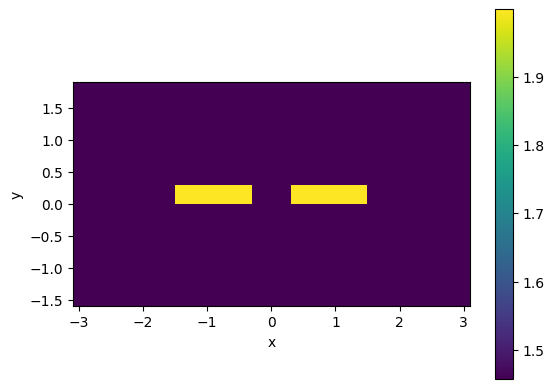

In [4]:
lambda_c = 1.55

dcoupler_cs = gt.modes.WaveguideCoupler(
    # Geometrical Parameters
    core_width=(1.2, 1.2), # Waveguide width
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    core_thickness=300 * nm, # Waveguide height 
    gap=600 * nm,
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=lambda_c, # Wavelength to simulate
    num_modes=4, # Number of modes to find
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    max_grid_scaling=1.5, # Parameters of the grid
    grid_resolution=20 # Parameters of the grid
)

dcoupler_cs.plot_index()

In [5]:
# calculate the coupling length for the first mode

dcoupler_neff = dcoupler_cs.n_eff.real
print(dcoupler_neff)


2026-11-13 09:27:17.869 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\WaveguideCoupler_cbc1bb971a882eda.npz.
[1.60942484 1.60116589 1.53540293 1.52057329]


In [6]:
dcoupler_cs.fraction_te
# first two modes are TE

array([0.994898  , 0.99527537, 0.00888064, 0.01130183])

In [7]:
dcoupler_cs.fraction_tm
# last two modes are TM

array([0.005102  , 0.00472463, 0.99111936, 0.98869817])

In [8]:
L_pi_TE = 0.5*lambda_c/(dcoupler_neff[0].real-dcoupler_neff[1].real)
print(L_pi_TE)

L_pi_TM = 0.5*lambda_c/(dcoupler_neff[2].real-dcoupler_neff[3].real)
print(L_pi_TM)

93.83767536699492
52.26022367744454


In [9]:
# calculate the coupling coefficient and plot for different L
L_TE = np.linspace(0, 4*L_pi_TE, 200)
L_TM = np.linspace(0, 4*L_pi_TM, 200)

K_TE = np.zeros(len(L_TE))
K_TM = np.zeros(len(L_TM))
for i in range(len(L_TE)): 
    K_TE[i] = (np.sin(np.pi*L_TE[i]/(2*L_pi_TE)))**2
for j in range(len(L_TM)):
    K_TM[j] = (np.sin(np.pi*L_TM[j]/(2*L_pi_TM)))**2 


<>:6: SyntaxWarning: invalid escape sequence '\p'
<>:14: SyntaxWarning: invalid escape sequence '\p'
<>:6: SyntaxWarning: invalid escape sequence '\p'
<>:14: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Nayan\AppData\Local\Temp\ipykernel_10412\2231602102.py:6: SyntaxWarning: invalid escape sequence '\p'
  axes[0].set_xlabel('$L/L_{\pi}$')
C:\Users\Nayan\AppData\Local\Temp\ipykernel_10412\2231602102.py:14: SyntaxWarning: invalid escape sequence '\p'
  axes[1].set_xlabel('$L/L_{\pi}$')


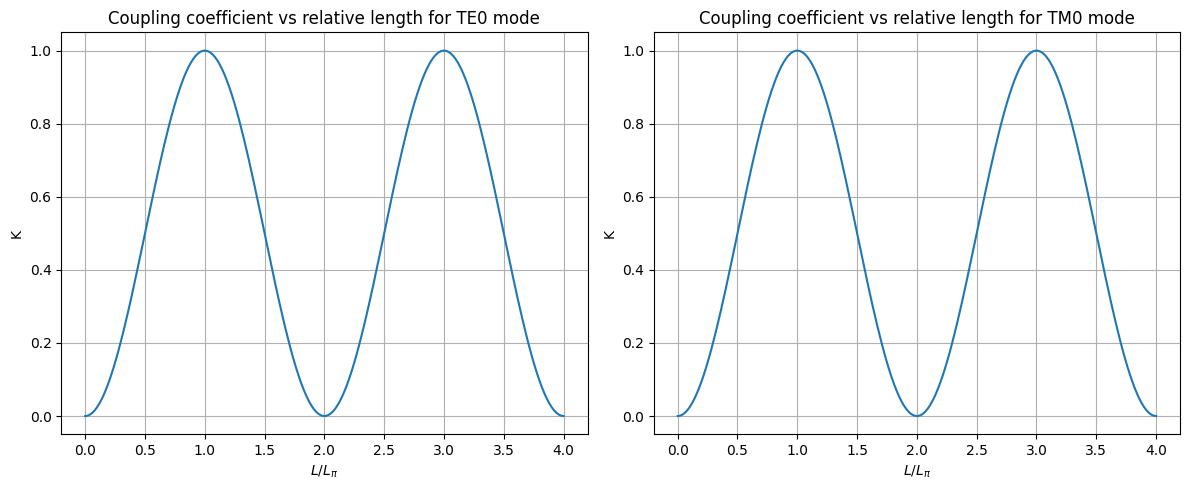

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# first subplot
axes[0].plot(L_TE / L_pi_TE, K_TE, label="TE mode")
axes[0].set_title('Coupling coefficient vs relative length for TE0 mode')
axes[0].set_xlabel('$L/L_{\pi}$')
axes[0].set_ylabel('K')
axes[0].grid()


# second subplot 
axes[1].plot(L_TM / L_pi_TM, K_TM, label="TM mode")
axes[1].set_title('Coupling coefficient vs relative length for TM0 mode')
axes[1].set_xlabel('$L/L_{\pi}$')
axes[1].set_ylabel('K')
axes[1].grid()

plt.tight_layout()
plt.show()

In [11]:
# calculate L needed for splittig power in half -> K = 0.5
# we clear L from the formula of K
# we calculate in terms of L_pi and then substitute numerically

K = 0.01
# TE0
L_half_Lpi_TE0 = 2*np.arcsin(np.sqrt(K))/np.pi
L_half_TE0 = 2*L_pi_TE*np.arcsin(np.sqrt(K))/np.pi
# TM0
L_half_Lpi_TM0 = 2*np.arcsin(np.sqrt(K))/np.pi
L_half_TM0 = 2*L_pi_TM*np.arcsin(np.sqrt(K))/np.pi

print("TE0 MODE: L for K = 0.5")
print(f'Distance relative to L_pi: {L_half_Lpi_TE0}\nAbsolute distance: {L_half_TE0}')
print("TM0 MODE:  L for K = 0.5")
print(f'Distance relative to L_pi: {L_half_Lpi_TM0}\nAbsolute distance: {L_half_TM0}')


TE0 MODE: L for K = 0.5
Distance relative to L_pi: 0.06376856085851985
Absolute distance: 5.983893512462244
TM0 MODE:  L for K = 0.5
Distance relative to L_pi: 0.06376856085851985
Absolute distance: 3.3325592540549827


## LO.2. 2x2 Directional Coupler

Here, you will use some functions provided by us (check **0. Imports** for more details) to simulate the propagation in a 2x2 directional coupler. Please read all the comments in the following code carefully and **make changes only to the lines marked with the #Student tag**

In [12]:
"""
No me va con el bucle

wg_gap = 0.6 # Student. Gap between waveguides um
wg_width_array = np.arange(0.6, 1.6+0.1, 0.1)
wg_N = 2

L_pi = []
for wg_width in wg_width_array: 
    d = wg_width + wg_gap

    m = DC_EME() # Here you instantiate a Directional Coupler to be simulated with the Eigen-mode expansion (EME) algorithm.
    m.MMI_num_modes = 12 # Number of modes to be calculated. Here, the higher, the better since we are going to calculate
                        # the propagation based on the mode decomposition. 
    m.DC_wg_gap = wg_gap # Gap between waveguides
    m.DC_wg_width = wg_width # Width of the waveguides core
    m.DC_N_waveguides = wg_N

    # 1) Compute de DC modes - Only execute whenever a geometrical parameter is changed. Takes time to find the modes. 
    m.find_all_modes()

    # 2) Get the L_pi 
    L_pi.append(m.get_L_pi())

for i in range(len(wg_width_array)):
    print(f'waveguide width: {wg_width_array[i]}, L_pi: {L_pi[i]}')"""



"\nNo me va con el bucle\n\nwg_gap = 0.6 # Student. Gap between waveguides um\nwg_width_array = np.arange(0.6, 1.6+0.1, 0.1)\nwg_N = 2\n\nL_pi = []\nfor wg_width in wg_width_array: \n    d = wg_width + wg_gap\n\n    m = DC_EME() # Here you instantiate a Directional Coupler to be simulated with the Eigen-mode expansion (EME) algorithm.\n    m.MMI_num_modes = 12 # Number of modes to be calculated. Here, the higher, the better since we are going to calculate\n                        # the propagation based on the mode decomposition. \n    m.DC_wg_gap = wg_gap # Gap between waveguides\n    m.DC_wg_width = wg_width # Width of the waveguides core\n    m.DC_N_waveguides = wg_N\n\n    # 1) Compute de DC modes - Only execute whenever a geometrical parameter is changed. Takes time to find the modes. \n    m.find_all_modes()\n\n    # 2) Get the L_pi \n    L_pi.append(m.get_L_pi())\n\nfor i in range(len(wg_width_array)):\n    print(f'waveguide width: {wg_width_array[i]}, L_pi: {L_pi[i]}')"

In [19]:
# Simulation flow for Directional Couplers
# Define your geometrical parameters here
wg_gap = 0.6 # Student. Gap between waveguides um
wg_width = 0.6 # Student. Core waveguides width um

d = wg_width + wg_gap
wg_N = 2

m = DC_EME() # Here you instantiate a Directional Coupler to be simulated with the Eigen-mode expansion (EME) algorithm.
m.MMI_num_modes = 12 # Number of modes to be calculated. Here, the higher, the better since we are going to calculate
                    # the propagation based on the mode decomposition. 
m.DC_wg_gap = wg_gap # Gap between waveguides
m.DC_wg_width = wg_width # Width of the waveguides core
m.DC_N_waveguides = wg_N

# 1) Compute de DC modes - Only execute whenever a geometrical parameter is changed. Takes time to find the modes. 
m.find_all_modes()

# 2) Get the L_pi 
L_pi = m.get_L_pi()
print("L_pi = ", L_pi, " µm")

c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


L_pi =  20.22824599463518  µm


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/405 [00:00<?, ?it/s]

------- Pameters -------
MMI length 20.2282
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.6912
Total OUT power: 0.6655
Excess loss [dB] =  1.7688
------------------------
Power over OUTs:  ['0.0034', '0.6620']
Ratio over OUTs ['0.0051', '0.9949']


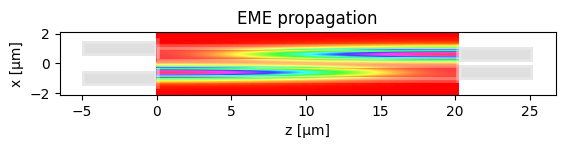

In [20]:
# IMPORTANT!!! 
# # If you DON'T change any geometrical parameter
# (waveguide widths or gap) you can skip last cell. 
# YOU CAN RUN the lines below as many times as you wish
# (SAVES TIME)

# 3) Configure DC
# DC I/O number
m.n_IN = 2
m.n_OUT = 2

m.L_MMI = abs(L_pi) # Since we use the same library for propagation simulations of MMI and DC 
                    # some variables might be identified as "MMI". Sorry about that (: 
                    # Might change in the future 

# L = L_pi: CROSS STATE
# L = 2*L_pi: BAR STATE
# L = 0.5*L_pi: 50/50

# 4) Run propagation - get power transfer and plot propagation
m.propagation()

<>:6: SyntaxWarning: invalid escape sequence '\p'
<>:6: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Nayan\AppData\Local\Temp\ipykernel_1560\1676139813.py:6: SyntaxWarning: invalid escape sequence '\p'
  plt.ylabel('$L_\pi$ calculated (um)')


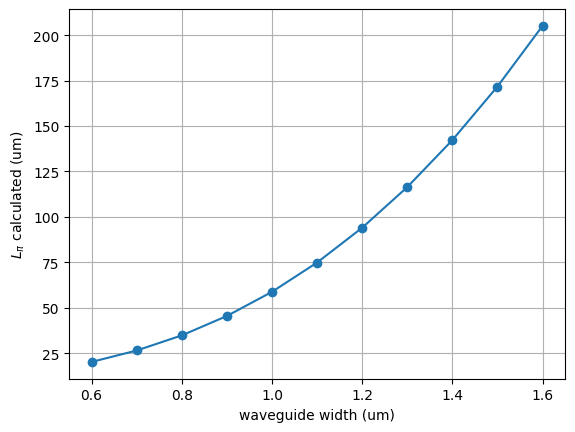

In [39]:
wg_width_array = np.arange(0.6, 1.6+0.1, 0.1)
L_pi = np.array([20.228, 26.513, 34.82, 45.497, 58.778, 74.890, 94.027, 116.404, 142.239, 171.73, 205.09])

plt.plot(wg_width_array, L_pi, 'o-')
plt.xlabel('waveguide width (um)')
plt.ylabel('$L_\pi$ calculated (um)')
plt.grid()
plt.show()

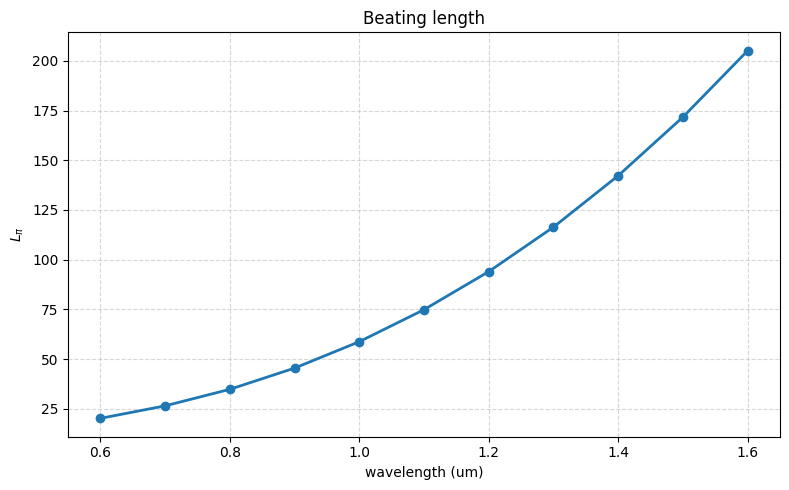

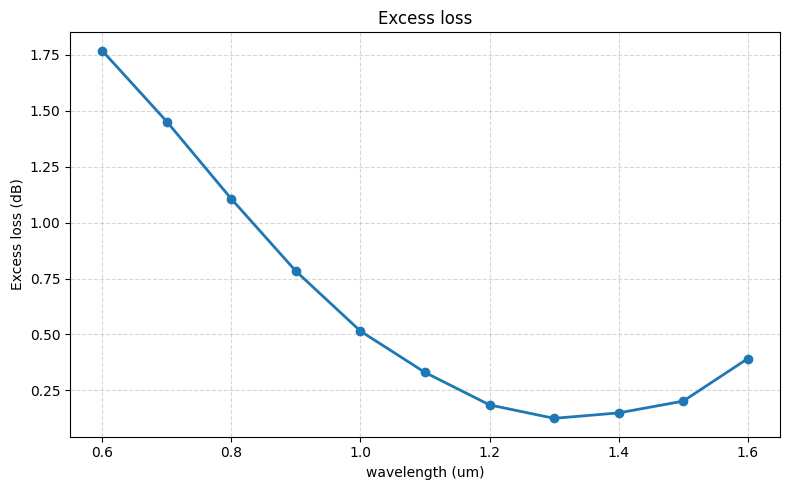

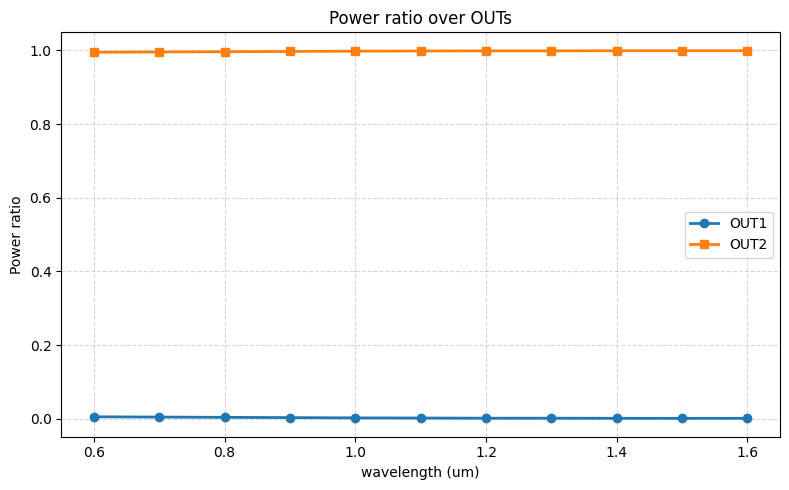

In [43]:
# ==========================================
# CROSS STATE - DATA
# ==========================================

# Input parameter
ww = np.array([
    0.6, 0.7, 0.8, 0.9, 1.0,
    1.1, 1.2, 1.3, 1.4, 1.5, 1.6
])

# MMI length (L_pi)
L_pi = np.array([
    20.2282, 26.5132, 34.8228, 45.4975, 58.7784,
    74.8903, 94.0274, 116.4042, 142.2393, 171.7255,
    205.0886
])

# Excess loss (dB)
excess_loss = np.array([
    1.7688, 1.4517, 1.1060, 0.7830, 0.5150,
    0.3302, 0.1851, 0.1250, 0.1493, 0.2020,
    0.3920
])

# Power ratio over OUTs
ratio_OUT1 = np.array([
    0.0051, 0.0043, 0.0036, 0.0029, 0.0021,
    0.0017, 0.0013, 0.0013, 0.0010, 0.0009,
    0.0010
])

ratio_OUT2 = np.array([
    0.9949, 0.9957, 0.9964, 0.9971, 0.9979,
    0.9983, 0.9987, 0.9987, 0.9990, 0.9991,
    0.9990
])


# ==========================================
# GRAPH 1 - MMI LENGTH
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(ww, L_pi, 'o-', linewidth=2, markersize=6)

plt.xlabel('wavelength (um)')
plt.ylabel(r'$L_{\pi}$')
plt.title('Beating length')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# ==========================================
# GRAPH 2 - EXCESS LOSS
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(ww, excess_loss, 'o-', linewidth=2, markersize=6)

plt.xlabel('wavelength (um)')
plt.ylabel('Excess loss (dB)')
plt.title('Excess loss')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# ==========================================
# GRAPH 3 - POWER RATIO OVER OUTs
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(ww, ratio_OUT1, 'o-', label='OUT1', linewidth=2)
plt.plot(ww, ratio_OUT2, 's-', label='OUT2', linewidth=2)

plt.xlabel('wavelength (um)')
plt.ylabel('Power ratio')
plt.title('Power ratio over OUTs')

plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## LO.3. Parallel uncoupled waveguides

In [ ]:
# HINT. Calculate manually the L_pi you may need to achieve K=0.01
# Then you can sweep the gap and calculate the L_pi until reaching 
# the desired value. 

In [44]:
# DEEP WAVEGUIDE

L = 10 # mm
K = 0.01
L_pi_goal = np.pi/2 * L / np.arcsin(np.sqrt(K))
print(f'Target L_pi: {L_pi_goal:.6f} mm')

Target L_pi: 156.817088 mm


In [48]:

# do the sweep manually (safer)
wg_gap = 3.55 # Student. Gap between waveguides um
wg_width = 1 # Student. Core waveguides width um

d = wg_width + wg_gap
wg_N = 2

In [ ]:
# plot K vs gap for L = 10mm to be uncoupled K<0.01
# the coarser sweep does not work: ValueError: Point is outside of the mesh.
 
wg_gap_array = np.linspace(3.5, 3.55, 10)
L_pi = []
for wg_gap in wg_gap_array:
    m = DC_EME() # Here you instantiate a Directional Coupler to be simulated with the Eigen-mode expansion (EME) algorithm.
    m.MMI_num_modes = 12 # Number of modes to be calculated. Here, the higher, the better since we are going to calculate
                        # the propagation based on the mode decomposition. 
    m.DC_wg_gap = wg_gap # Gap between waveguides
    m.DC_wg_width = wg_width # Width of the waveguides core
    m.DC_N_waveguides = wg_N

    # 1) Compute de DC modes - Only execute whenever a geometrical parameter is changed. Takes time to find the modes. 
    m.find_all_modes()

    # 2) Get the L_pi 
    L_pi.append(m.get_L_pi())

c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


ValueError: Point is outside of the mesh.

ValueError: x and y must have same first dimension, but have shapes (20,) and (0,)

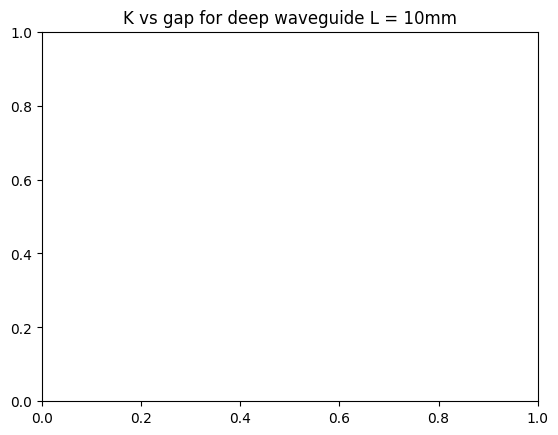

In [46]:
L = 10e3
K = []
for L_pi_value in L_pi:
    K.append(np.sin(np.pi/2 * L/L_pi_value)**2)

plt.title('K vs gap for deep waveguide L = 10mm')
plt.plot(wg_gap_array, K, 'o-')
plt.hlines(0.01, wg_gap_array[0], wg_gap_array[-1], color='black', linestyles='--', label='K = 0.01')
plt.xlabel('gap (um)')
plt.ylabel('K')
plt.legend()
plt.grid()

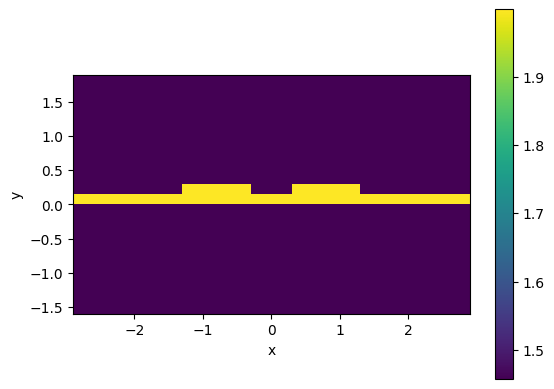

In [5]:
# SHALLOW WAVEGUIDE: we cannot do it with the functions provided, we must do it manually
# try with different values until reach close
lambda_c = 1.55 # um
dcoupler_cs = gt.modes.WaveguideCoupler(
    # Geometrical Parameters
    core_width=(1.0, 1.0), # Waveguide width
    slab_thickness=150 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    core_thickness=300 * nm, # Waveguide height 
    gap=600 * nm,
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=lambda_c, # Wavelength to simulate
    num_modes=2, # Number of modes to find
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    max_grid_scaling=1.5, # Parameters of the grid
    grid_resolution=20 # Parameters of the grid
)

dcoupler_cs.plot_index()


In [6]:
dcoupler_neff = dcoupler_cs.n_eff.real
print(dcoupler_neff)

print(dcoupler_cs.fraction_te)
print(dcoupler_cs.fraction_tm)

c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

09:19:54 Hora estándar Europa Occidental WARNING: The group index was not       
                                         computed. To calculate group index,    
                                         pass 'group_index_step = True' in the  
                                         'ModeSpec'.                            

2026-11-12 09:19:54.873 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_afd147a0c68d457e.npz.
[1.61593334 1.59618939]
[0.99608423 0.99590382]
[0.00391577 0.00409618]


In [7]:
L_pi = 0.5*lambda_c/(dcoupler_neff[0].real-dcoupler_neff[1].real)
print(L_pi) # um

39.252528878866066


In [ ]:
# calculate L_pi manually for each gap
# do a list 
# then calculate K and plot
lambda_c = 1.55 # um

dcoupler_cs = gt.modes.WaveguideCoupler(
    # Geometrical Parameters
    core_width=(1.0, 1.0), # Waveguide width
    slab_thickness=150 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    core_thickness=300 * nm, # Waveguide height 
    gap=1.15,
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=lambda_c, # Wavelength to simulate
    num_modes=2, # Number of modes to find
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    max_grid_scaling=1.5, # Parameters of the grid
    grid_resolution=20 # Parameters of the grid
)

print(dcoupler_cs.fraction_te)

dcoupler_neff = dcoupler_cs.n_eff.real
L_pi = 0.5*lambda_c/(dcoupler_neff[0].real-dcoupler_neff[1].real)
print(L_pi) # um

2026-11-12 22:22:10.148 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\WaveguideCoupler_db6c6f6a385749d8.npz.
[0.99684075 0.99678581]
171.04157319753526


In [54]:
# %% capture

gap_array = np.linspace(4.6, 5, 10)
L_pi = []
for gap in gap_array: 
    dcoupler_cs = gt.modes.WaveguideCoupler(
    # Geometrical Parameters
    core_width=(1.0, 1.0), # Waveguide width
    slab_thickness=150 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    core_thickness=300 * nm, # Waveguide height 
    gap=gap,
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=lambda_c, # Wavelength to simulate
    num_modes=2, # Number of modes to find
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    max_grid_scaling=1.5, # Parameters of the grid
    grid_resolution=20 # Parameters of the grid
    )   

    dcoupler_neff = dcoupler_cs.n_eff.real
    L_pi.append(0.5*lambda_c/(dcoupler_neff[0].real-dcoupler_neff[1].real))

print(L_pi) # um

2026-11-13 23:39:42.503 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\WaveguideCoupler_cc5168012b44d67b.npz.


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

2026-11-13 23:39:49.347 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_4c12408c57dfb6f5.npz.


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

2026-11-13 23:39:58.773 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_4ef1fd5586e21f85.npz.


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

... (9 outputs left out)

c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

2026-11-13 23:40:54.858 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_0caeaf588a2f2c34.npz.


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

2026-11-13 23:41:04.003 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_24f7ef877f03de54.npz.
[np.float64(84431.9114946905), np.float64(91711.47565784055), np.float64(100219.3198880918), np.float64(109644.86507009724), np.float64(117906.35189390872), np.float64(128060.97177387563), np.float64(138536.45220579958), np.float64(150224.7766619855), np.float64(163244.67143448786), np.float64(180078.80701357534)]


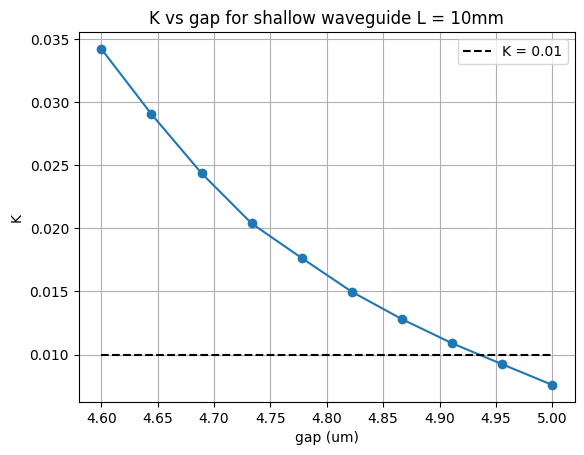

In [55]:
L = 10e3
K = []
for L_pi_value in L_pi:
    K.append(np.sin(np.pi/2 * L/L_pi_value)**2)

plt.title('K vs gap for shallow waveguide L = 10mm')
plt.plot(gap_array, K, 'o-')
plt.hlines(0.01, gap_array[0], gap_array[-1], color='black', linestyles='--', label='K = 0.01')
plt.xlabel('gap (um)')
plt.ylabel('K')
plt.grid()
plt.legend()

## LO.4. 2x2 Multimode Interference Coupler

### LO.4.1 Propagation Simulation

For the multimode interference (MMI) couplers we must rely on the design tables shown on the theoretical session: 

<img src="mmi.png" alt="Design tables for MMI couplers" width="600">

Here, you will use some functions provided by us (check **0. Imports** for more details) to simulate the propagation in a 2x2 directional coupler. Please read all the comments in the following code carefully and **make changes only to the lines marked with the #Student tag**

In [56]:
# Simulation flow for MMI Couplers
# Define your geometrical parameters here
mmi_Width = 6.6 # Student. Body width

m = MMI_EME() # Here you instantiate a MMI to be simulated with the Eigen-mode expansion (EME) algorithm.
m.MMI_width = mmi_Width
m.MMI_num_modes = 25 # Number of modes to be calculated. Here, the higher, the better since we are going to calculate
                    # the propagation based on the mode decomposition. 

# 1) Compute de MMI body modes - Only execute whenever a geometrical parameter is changed. Takes time to find the modes. 
m.find_all_modes()

# 2) Get the L_pi 
L_pi = m.get_L_pi()
print("L_pi = ", L_pi, " µm")

c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


L_pi =  69.03598607256005  µm


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/690 [00:00<?, ?it/s]

------- Pameters -------
MMI length 34.5180
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9604
Total OUT power: 0.9075
Excess loss [dB] =  0.4217
------------------------
Power over OUTs:  ['0.4675', '0.4399']
Ratio over OUTs ['0.5152', '0.4848']


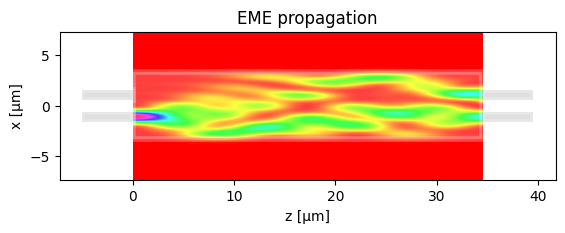

In [61]:
# IMPORTANT!!! 
# # If you DON'T change neither the MMI width 
# nor input/output waveguide widths
# YOU CAN RUN the lines below as many times as you wish
# (SAVES TIME)

# 3) Configure MMI
# # MMI I/O number (check class slides for type of MMI) 
# 2x2 MMI
m.n_IN =  2 # STUDENT
m.n_OUT = 2 # STUDENT

# MMI I/O waveguide positions (check class slides for type of MMI)
m.IN_WVG_positions = [-m.MMI_width/6, m.MMI_width/6] # STUDENT
m.OUT_WVG_positions = [-m.MMI_width/6, m.MMI_width/6] # STUDENT

# MMI length (check class slides for type of MMI)
m.L_MMI = 0.5*abs(L_pi) # STUDENT

# Run propagation
m.propagation()

### LO.4.2. 2x2 Multimode Interference Coupler - Optimization

The strategy here is to run loops of first dL and then dy for different values. Once an optimal value of dL is found, we fix it and test with dy. 

The first values to test generate a more corase grid while the following iterations look for a more refined and precise analysis. The last one is shown for sake of abreviation. 

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/690 [00:00<?, ?it/s]

------- Pameters -------
MMI length 34.5180
MMI length increment 0.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9448
Total OUT power: 0.5440
Excess loss [dB] =  2.6444
------------------------
Power over OUTs:  ['0.0402', '0.5037']
Ratio over OUTs ['0.0740', '0.9260']


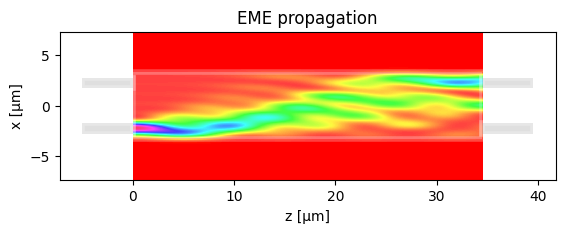

In [ ]:
###########################################
# TEST 1 ITERATION
###########################################

dy = 1.15 # increment distance of the position of the waveguides (offset)

# MMI I/O waveguide positions (check class slides for type of MMI)
m.IN_WVG_positions = [-m.MMI_width/6 - dy, m.MMI_width/6 + dy] # STUDENT
m.OUT_WVG_positions = [-m.MMI_width/6 - dy, m.MMI_width/6 + dy] # STUDENT

# MMI length (check class slides for type of MMI)
# length increment wrt the previous case
m.dL_MMI = 0 # STUDENT

# Run propagation
m.propagation()

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/670 [00:00<?, ?it/s]

------- Pameters -------
MMI length 34.5180
MMI length increment -1.0000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9604
Total OUT power: 0.8924
Excess loss [dB] =  0.4946
------------------------
Power over OUTs:  ['0.4474', '0.4450']
Ratio over OUTs ['0.5013', '0.4987']


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/674 [00:00<?, ?it/s]

------- Pameters -------
MMI length 34.5180
MMI length increment -0.8333
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9604
Total OUT power: 0.8994
Excess loss [dB] =  0.4603
------------------------
Power over OUTs:  ['0.4528', '0.4466']
Ratio over OUTs ['0.5035', '0.4965']


... (20 outputs left out)

------- Pameters -------
MMI length 34.5180
MMI length increment 0.3333
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9604
Total OUT power: 0.8977
Excess loss [dB] =  0.4686
------------------------
Power over OUTs:  ['0.4664', '0.4314']
Ratio over OUTs ['0.5195', '0.4805']


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/700 [00:00<?, ?it/s]

------- Pameters -------
MMI length 34.5180
MMI length increment 0.5000
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9604
Total OUT power: 0.8902
Excess loss [dB] =  0.5051
------------------------
Power over OUTs:  ['0.4641', '0.4261']
Ratio over OUTs ['0.5214', '0.4786']


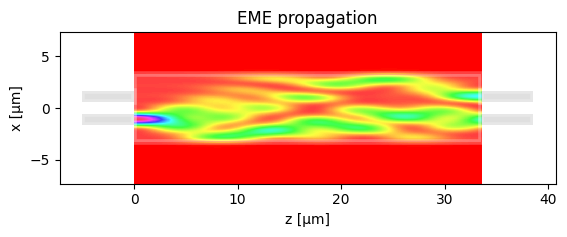

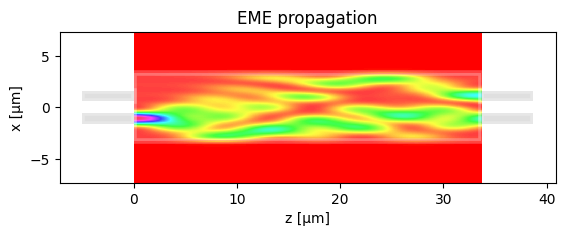

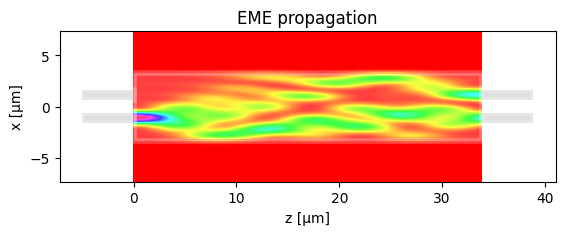

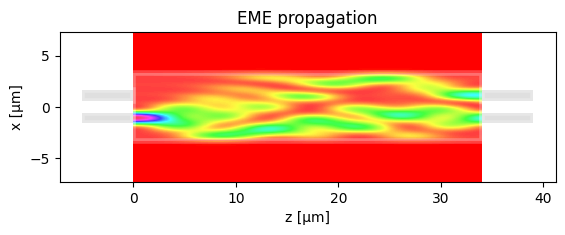

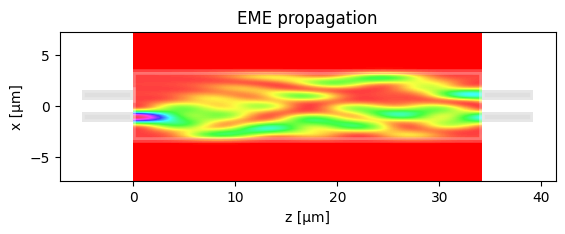

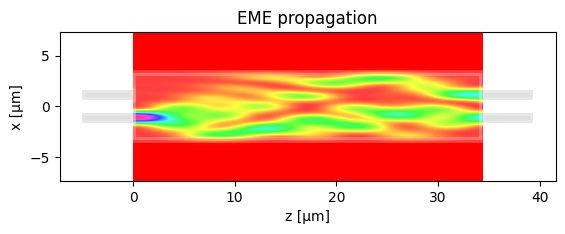

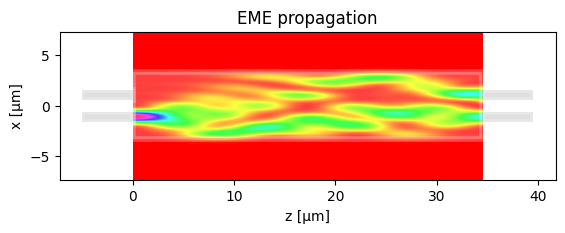

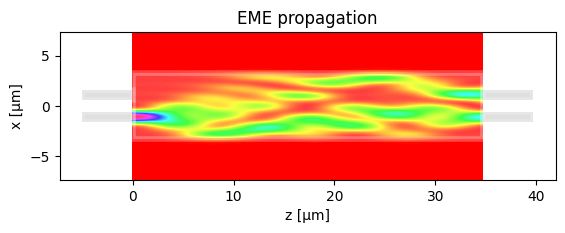

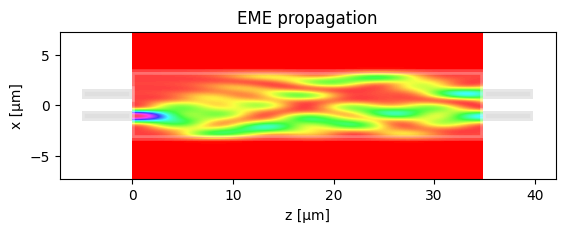

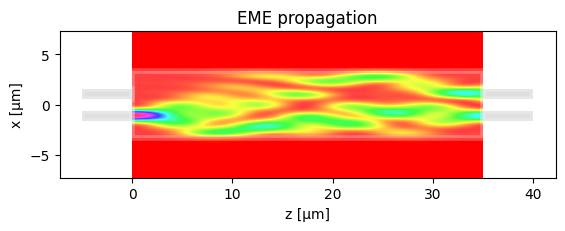

In [55]:
dL_range = np.linspace(-1, 0.5, 10) 
dy = 0
for dL in dL_range: 

    # MMI I/O waveguide positions (check class slides for type of MMI)
    m.IN_WVG_positions = [-m.MMI_width/6 - dy, m.MMI_width/6 + dy] # STUDENT
    m.OUT_WVG_positions = [-m.MMI_width/6 - dy, m.MMI_width/6 + dy] # STUDENT

    # MMI length (check class slides for type of MMI)
    # length increment wrt the previous case
    m.dL_MMI = dL # STUDENT

    # Run propagation
    m.propagation()

$dL = -0.33$

0.0


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/684 [00:00<?, ?it/s]

------- Pameters -------
MMI length 34.5180
MMI length increment -0.3300
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9604
Total OUT power: 0.9099
Excess loss [dB] =  0.4103
------------------------
Power over OUTs:  ['0.4645', '0.4454']
Ratio over OUTs ['0.5105', '0.4895']
0.011111111111111112


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/684 [00:00<?, ?it/s]

... (21 outputs left out)

------- Pameters -------
MMI length 34.5180
MMI length increment -0.3300
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9535
Total OUT power: 0.9094
Excess loss [dB] =  0.4125
------------------------
Power over OUTs:  ['0.4625', '0.4469']
Ratio over OUTs ['0.5086', '0.4914']
0.1


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/684 [00:00<?, ?it/s]

------- Pameters -------
MMI length 34.5180
MMI length increment -0.3300
IO wg width 1.0000
IO wg width increment 0.0000
------------------------
Total power IN coupled 0.9524
Total OUT power: 0.9043
Excess loss [dB] =  0.4369
------------------------
Power over OUTs:  ['0.4599', '0.4444']
Ratio over OUTs ['0.5085', '0.4915']


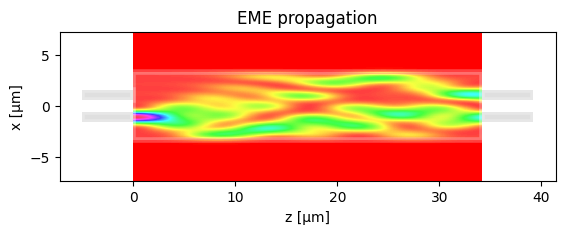

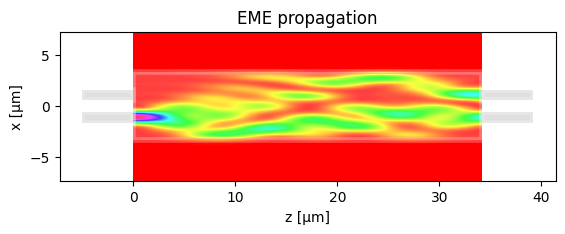

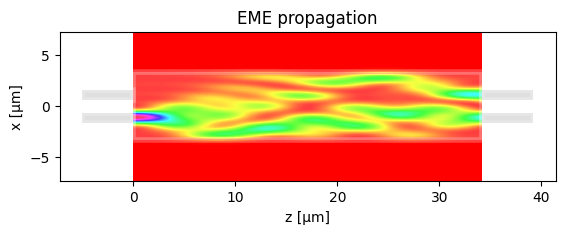

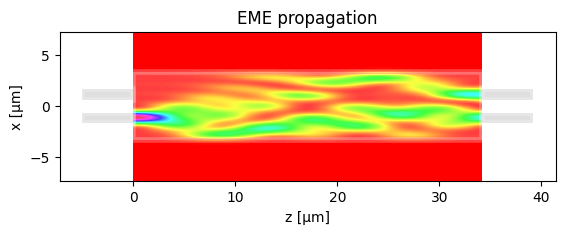

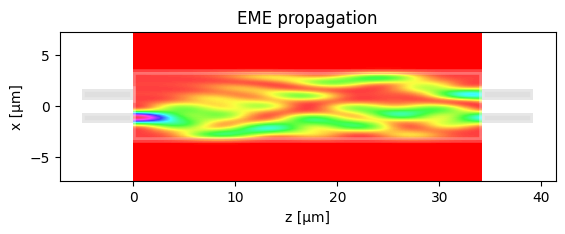

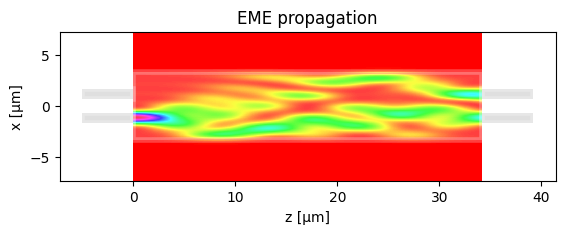

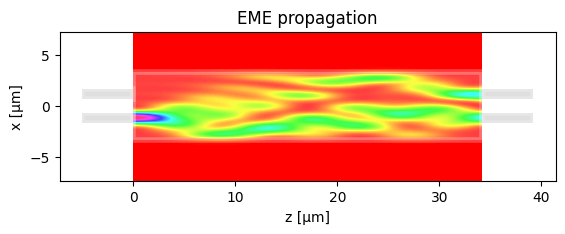

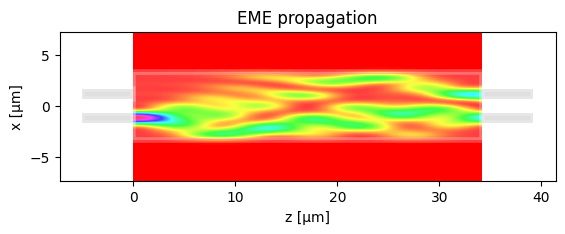

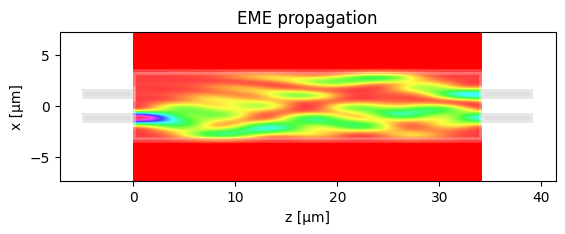

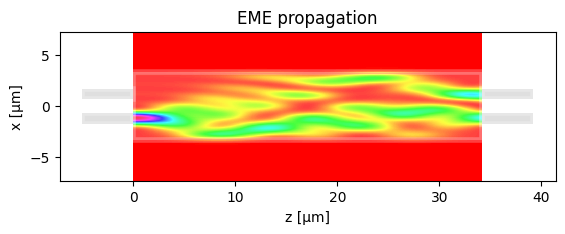

In [56]:
# more refined sweep
dy_range = np.linspace(0, 0.1, 10) # waveguide wdith = 1.0 um
for dy in dy_range: 
    print(dy)
    
    # MMI I/O waveguide positions (check class slides for type of MMI)
    m.IN_WVG_positions = [-m.MMI_width/6 - dy, m.MMI_width/6 + dy] # STUDENT
    m.OUT_WVG_positions = [-m.MMI_width/6 - dy, m.MMI_width/6 + dy] # STUDENT

    # MMI length (check class slides for type of MMI)
    # length increment wrt the previous case
    m.dL_MMI = -0.33 # STUDENT

    # Run propagation
    m.propagation()

According to the results obtained above, the best result for small losses we can get is around $dy = [0.044, 0.055]$
And now I will repeat it because I noticed that first we shoud modify dL. It seems that they are still the smallest values after optimizing dL. 

In conclusion, the best combination achieved is $dL = -0.3333 um $ and $dy = 0.050 um$ with Excess loss [dB] =  0.3801 and Ratio over OUTs ['0.5092', '0.4908'] which improves losses in 0.2846 dB and ratio over outputs around 2%. 

### LO.4.3 2x2 Multimode Interference Coupler – Optimization (II)

In [59]:
# Design flow for MMI
# original values: MMI_width = 6.6 um, wg_width = 1 um

m = MMI_EME()
m.MMI_width = 8  # MMI width
m.wg_width_dw = 1.1 # STUDENT

# 1) Compute de MMI modes
m.find_all_modes()

# 2) Get the L_pi
L_pi = m.get_L_pi()
print("L_pi = ", L_pi, " µm")

c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


L_pi =  99.8480564016238  µm


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/992 [00:00<?, ?it/s]

------- Pameters -------
MMI length 49.9240
MMI length increment -0.3333
IO wg width 1.0000
IO wg width increment 1.1000
------------------------
Total power IN coupled 0.9995
Total OUT power: 0.9951
Excess loss [dB] =  0.0212
------------------------
Power over OUTs:  ['0.5089', '0.4862']
Ratio over OUTs ['0.5114', '0.4886']


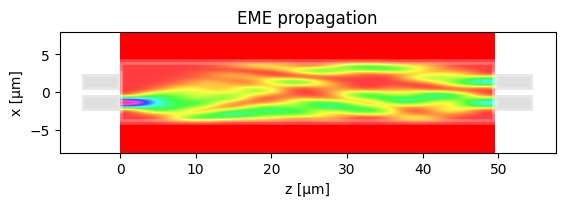

In [60]:
# 3) Configure MMI
# # MMI I/O number (check class slides for type of MMI)
m.n_IN = 2 # STUDENT
m.n_OUT = 2 # STUDENT

dy = 0.050
# MMI I/O waveguide positions (check class slides for type of MMI)
m.IN_WVG_positions = [-m.MMI_width/6-dy, m.MMI_width/6+dy] # STUDENT
m.OUT_WVG_positions = [-m.MMI_width/6-dy, m.MMI_width/6+dy] # STUDENT

# MMI length (check class slides for type of MMI)
m.L_MMI = L_pi/2  # STUDENT
m.dL_MMI = -0.3333 # STUDENT

# Run propagation
m.propagation()

## LO.5. 1x4 1x4 Multimode Interference Coupler 

Repeat the design procedure explained for the 2x2 Coupler to design a 1x4 MMI Coupler. Consider: 
- Select a suitable MMI body width, taking into account that you now must allocate 4 waveguides at the output. 
- Minimize the losses and output imbalance for the MMI coupler. 

c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


L_pi =  384.7075420720182  µm


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/1436 [00:00<?, ?it/s]

------- Pameters -------
MMI length 72.1327
MMI length increment -0.3333
IO wg width 1.0000
IO wg width increment 1.2000
------------------------
Total power IN coupled 0.9898
Total OUT power: 0.9626
Excess loss [dB] =  0.1654
------------------------
Power over OUTs:  ['0.2442', '0.2370', '0.2370', '0.2444']
Ratio over OUTs ['0.2537', '0.2462', '0.2462', '0.2539']


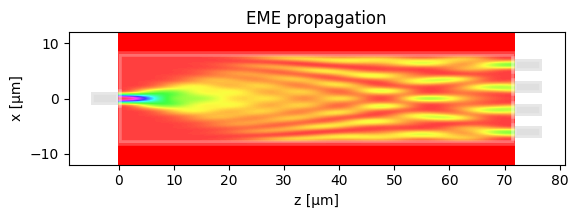

In [9]:
# Design flow for MMI

m = MMI_EME()
m.MMI_width = 16  # MMI width
m.wg_width_dw = 1.2 # STUDENT

# 1) Compute de MMI modes
m.find_all_modes()

# 2) Get the L_pi
L_pi = m.get_L_pi()
print("L_pi = ", L_pi, " µm")

# 3) Configure MMI
# # MMI I/O number (check class slides for type of MMI)
m.n_IN = 1 # STUDENT
m.n_OUT = 4 # STUDENT

dy = 0.3
# MMI I/O waveguide positions (check class slides for type of MMI)
m.IN_WVG_positions = [0] # STUDENT
m.OUT_WVG_positions = [-3.6*m.MMI_width/10-dy, -1.1*m.MMI_width/10-dy, 1.1*m.MMI_width/10+dy, 3.6*m.MMI_width/10+dy] # STUDENT

# MMI length (check class slides for type of MMI)
m.L_MMI = 3*L_pi/(4*4)  # STUDENT: from the table of MMI
m.dL_MMI = -0.3333 # STUDENT

# Run propagation
m.propagation()

## Extra - Exercises

### E1. Directional coupler wavelength dependence

In [30]:
wavelength_range = np.linspace(1.5, 1.7, 10) # STUDENT code goes here

L_pi_TE_wvl = []
L_pi_TM_wvl = []

for wavelength in wavelength_range: 
    deep_dcoupler_cs = gt.modes.WaveguideCoupler(
        wavelength=wavelength, # Wavelength to simulate - Must be a vector
        core_width=(1.0, 1.0), # Waveguide width
        gap=600 * nm,
        slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        core_thickness=300 * nm, # Waveguide height 
        num_modes=4, # Number of modes to find
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
        max_grid_scaling=1.5, # Parameters of the grid
        grid_resolution=20 # Parameters of the grid
    )

    deep_dcoupler_neff = deep_dcoupler_cs.n_eff.real
    print(deep_dcoupler_cs.fraction_te)
    L_pi_TE_wvl.append(0.5*lambda_c/(deep_dcoupler_neff[0]-deep_dcoupler_neff[1]))
    L_pi_TM_wvl.append(0.5*lambda_c/(deep_dcoupler_neff[2]-deep_dcoupler_neff[3]))

print(L_pi_TE_wvl) # um
print(L_pi_TM_wvl) # um


2026-11-13 23:08:51.665 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\WaveguideCoupler_fc2c62c75e0d5f6e.npz.
[0.99310671 0.99329003 0.01004049 0.01294311]
2026-11-13 23:08:51.678 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\WaveguideCoupler_29c0634ea7d6d4d9.npz.
[0.99350243 0.99371797 0.01005513 0.01313712]
2026-11-13 23:08:51.712 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\WaveguideCoupler_58085fbfcac895a7.npz.
[0.99281482 0.99293854 0.01010586 0.01319383]
2026-11-13 23:08:51.755 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\WaveguideCoupler_54a3fbdb8f3d556b.npz.
[0.99276885 0.99282305 0.01017711 0.01331649]
2026-11-13 23:08:51.791 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\WaveguideCoupler_429bbc17810eecfc.npz.
[0.99293489 0.9930533  0.00966006 0.01279616]
2026-11-13 23:08:51.833 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\WaveguideCoupler_

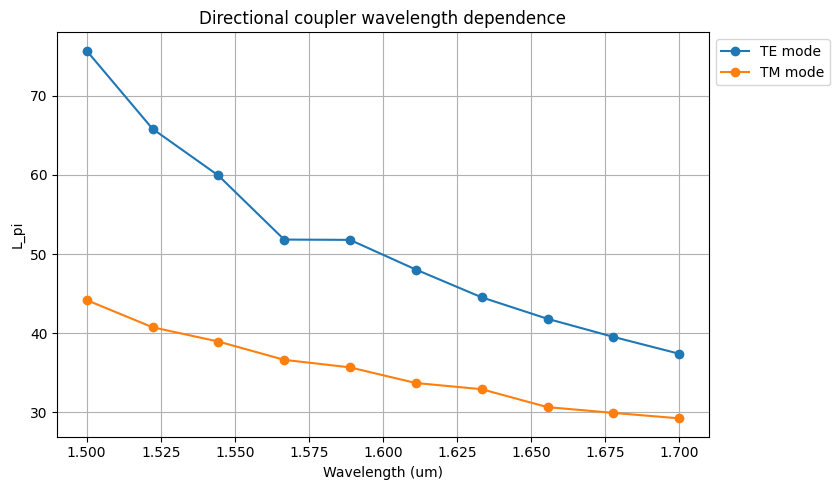

In [36]:
plt.figure(figsize=(10, 5))
plt.title('Directional coupler wavelength dependence')
# plt.scatter(wavelength, L_pi_TE,edgecolors='k',facecolors='none',label = '__nolegend__')
plt.plot(wavelength_range, L_pi_TE_wvl, 'o-', label='TE mode')
plt.plot(wavelength_range, L_pi_TM_wvl, 'o-', label='TM mode')
plt.xlabel("Wavelength (um)")
plt.ylabel("L_pi")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

### E2. Directional coupler gap dependence

In [25]:
print(gap_range)

[0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8 2.  2.2 2.4]


In [37]:
lambda_c = 1.55
gap_range = np.arange(0.2, 2.4+0.2, 0.2)
# gap_to_simulate = 600 * nm # STUDENT. You can manually change the gap
                            # or you can sweep the parameter using a Python for loop. 


L_pi_TE_gap = []
L_pi_TM_gap = []
for gap in gap_range: 
    deep_dcoupler_cs = gt.modes.WaveguideCoupler(
        wavelength=wavelength, # Wavelength to simulate - Must be a vector
        core_width=(1.0, 1.0), # Waveguide width
        gap=gap,
        slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        core_thickness=300 * nm, # Waveguide height 
        num_modes=4, # Number of modes to find
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
        max_grid_scaling=1.5, # Parameters of the grid
        grid_resolution=20 # Parameters of the grid
    )
    deep_dcoupler_neff = deep_dcoupler_cs.n_eff.real
    print(deep_dcoupler_cs.fraction_te)
    L_pi_TE_gap.append(0.5*lambda_c/(deep_dcoupler_neff[0]-deep_dcoupler_neff[1]))
    L_pi_TM_gap.append(0.5*lambda_c/(deep_dcoupler_neff[2]-deep_dcoupler_neff[3]))

print(L_pi_TE_gap) # um
print(L_pi_TM_gap) # um


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

2026-11-13 23:11:15.354 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_eed9751d0bda5ab0.npz.
[0.99358904 0.99160262 0.00739194 0.01422864]


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

2026-11-13 23:11:19.148 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_c0a9b0681c999cf1.npz.
[0.99256784 0.99240457 0.00838046 0.01313748]


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

2026-11-13 23:11:22.886 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_455c4a493ae8f281.npz.
[0.99210347 0.99202658 0.00914207 0.01233124]


... (14 outputs left out)

c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

2026-11-13 23:11:59.442 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_c29e224f491a1ad9.npz.
[0.99228401 0.99116008 0.01012885 0.01058048]


c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\Users\Nayan\LAB_DESIGN\pic-upv-lab2\.venv\Lib\site-packages\tidy3d\components\mode\d

2026-11-13 23:12:05.516 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache\WaveguideCoupler_a92920d80f68b9e1.npz.
[0.99230932 0.99176063 0.0101168  0.01051482]
[np.float64(13.916795317343723), np.float64(23.250061636650837), np.float64(37.38748819182869), np.float64(59.78664785600245), np.float64(92.95582486169396), np.float64(148.44385798131103), np.float64(229.1360023745117), np.float64(346.9931965811204), np.float64(503.5696762292983), np.float64(682.748500506952), np.float64(499.7006034723902), np.float64(961.241904544172)]
[np.float64(15.111291251892913), np.float64(20.642851953294702), np.float64(29.221492228536224), np.float64(40.21973248559825), np.float64(53.70991877197631), np.float64(72.16774347515921), np.float64(99.464690673372), np.float64(128.78928187927175), np.float64(173.91087060950682), np.float64(226.16329533803557), np.float64(239.63423779135613), np.float64(363.1679932369167)]


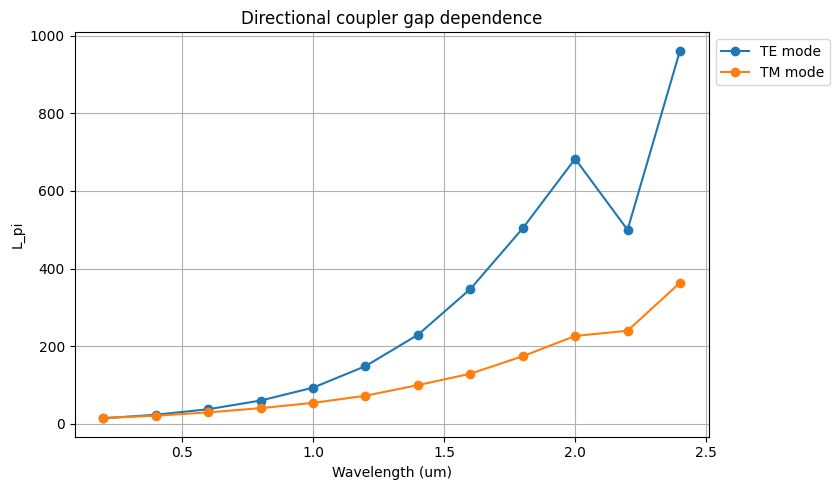

In [38]:
# STUDENT. Plot goes here
# L_pi_TE[-1] = None

plt.figure(figsize=(10, 5))
plt.title('Directional coupler gap dependence')
# plt.scatter(wavelength, L_pi_TE,edgecolors='k',facecolors='none',label = '__nolegend__')
plt.plot(gap_range, L_pi_TE_gap, 'o-', label='TE mode')
plt.plot(gap_range, L_pi_TM_gap, 'o-', label='TM mode')
plt.xlabel("Wavelength (um)")
plt.ylabel("L_pi")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

### E3. MMI coupler wavelength dependence

In [68]:
mmi_body_w = 6.6 
lambda_range = np.linspace(1.5, 1.7, 10) # STUDENT code goes here.

L_pi_TE_wvl = []
L_pi_TM_wvl = []

for lambda_c in lambda_range: 
    mmi_body_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=mmi_body_w, # MMI Body width
        core_thickness=300 * nm, # MMI Body height 
        slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguides.
        # Materials
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=lambda_c, # Wavelength to simulate
        num_modes=15, # Targeted number of modes to find - Higher than before! It's a multimode section
        max_grid_scaling=1.5, # Parameters of the grid
        grid_resolution=20, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    mmi_body_waveguide_neff = mmi_body_waveguide.n_eff.real
    print(mmi_body_waveguide.fraction_te)
    L_pi_TE_wvl.append(0.5*lambda_c/(mmi_body_waveguide_neff[0]-mmi_body_waveguide_neff[1]))
    L_pi_TM_wvl.append(0.5*lambda_c/(mmi_body_waveguide_neff[5]-mmi_body_waveguide_neff[6]))

print(L_pi_TE_wvl) # um
print(L_pi_TM_wvl) # um



2026-11-14 00:17:06.895 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_9a2f1ddbafc80a93.npz.
[9.99956803e-01 9.99820973e-01 9.99571961e-01 9.99168361e-01
 9.98532424e-01 7.19259753e-04 2.83263144e-03 9.97512383e-01
 6.20492457e-03 1.05985535e-02 9.95769195e-01 1.56195726e-02
 9.92097477e-01 2.03991541e-02 1.77199632e-03]
2026-11-14 00:17:06.909 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_7121c473dc49b9ad.npz.
[9.99952747e-01 9.99803849e-01 9.99529623e-01 9.99081531e-01
 9.98362022e-01 7.36899720e-04 2.89444905e-03 9.89721622e-01
 1.42932035e-02 1.07419926e-02 9.95056634e-01 1.56161645e-02
 1.98860954e-02 9.88671066e-01 7.63971832e-03]
2026-11-14 00:17:06.920 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_575894a07b1f245e.npz.
[9.99954522e-01 9.99810832e-01 9.99544723e-01 9.99105933e-01
 9.98389419e-01 7.42315370e-04 2.91531603e-03 1.00678282e-02
 9.93723101e-01 1.07331349e-02 9.94959742e-

[9.99941570e-01 9.99757110e-01 9.99416105e-01 9.98855654e-01
 7.56591123e-04 9.97952424e-01 2.96278959e-03 6.42430307e-03
 9.96441232e-01 1.07928900e-02 1.54342530e-02 9.93467986e-01
 1.83246199e-02 1.46869639e-02 9.83691231e-01]
2026-11-14 00:17:06.947 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_582842357da87f13.npz.
[9.99950656e-01 9.99794303e-01 9.99503011e-01 9.99017900e-01
 9.98206172e-01 7.54088080e-04 2.96660659e-03 6.62076324e-03
 9.96638368e-01 1.07494744e-02 1.53328365e-02 9.94089847e-01
 1.80373949e-02 3.74733424e-02 9.74047838e-01]
2026-11-14 00:17:06.958 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_58d7c8d99f3ad06e.npz.
[9.99943838e-01 9.99765927e-01 9.99434634e-01 9.98883270e-01
 9.97955309e-01 7.64656790e-04 3.01099819e-03 6.56056334e-03
 9.96316298e-01 1.07782047e-02 1.52221638e-02 9.93173819e-01
 9.55093824e-03 1.68838459e-02 9.86249167e-01]
2026-11-14 00:17:06.970 | INFO     | gplugins.tidy3d.modes:_

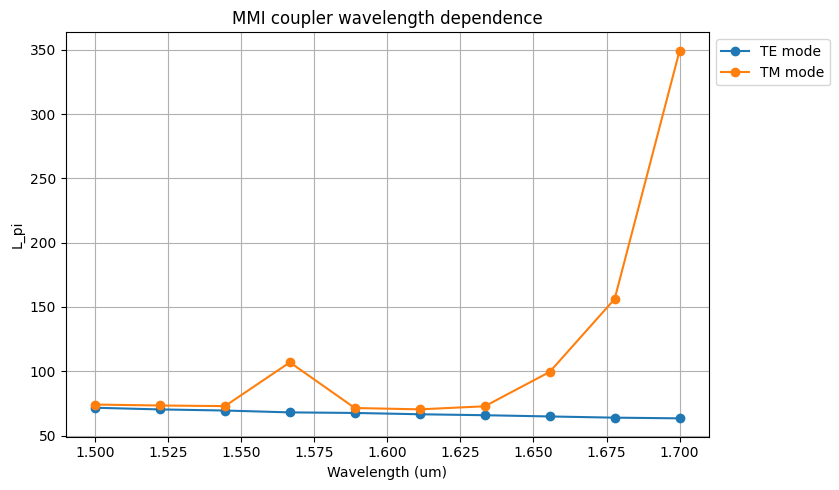

In [69]:
plt.figure(figsize=(10, 5))
plt.title('MMI coupler wavelength dependence')
# plt.scatter(wavelength, L_pi_TE,edgecolors='k',facecolors='none',label = '__nolegend__')
plt.plot(wavelength_range, L_pi_TE_wvl, 'o-', label='TE mode')
plt.plot(wavelength_range, L_pi_TM_wvl, 'o-', label='TM mode')
plt.xlabel("Wavelength (um)")
plt.ylabel("L_pi")
plt.grid()
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])

### E4. MMI coupler body width dependence

In [75]:
lambda_c = 1.55

# mmi_body_w = 6.6 # STUDENT. You can manually change the body width
                 # or you can sweep the parameter using a Python for loop. 

mmi_body_w_array = np.arange(5, 10+0.5, 0.5)

L_pi_TE_gap = []
L_pi_TM_gap = []

for mmi_body_w in mmi_body_w_array:
    mmi_body_waveguide = gt.modes.Waveguide(
        # Geometrical Parameters
        core_width=mmi_body_w, # MMI Body width
        core_thickness=300 * nm, # MMI Body height 
        slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguides.
        # Materials
        core_material='sin', #  Material of the waveguide
        clad_material='sio2', # Surrounding material
        # Modesolver Parameters
        wavelength=lambda_c, # Wavelength to simulate
        num_modes=15, # Targeted number of modes to find - Higher than before! It's a multimode section
        max_grid_scaling=1.5, # Parameters of the grid
        grid_resolution=20, # Parameters of the grid
        cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
        precision='double',
    )

    mmi_body_waveguide_neff = mmi_body_waveguide.n_eff.real
    print(mmi_body_waveguide.fraction_te)
    L_pi_TE_gap.append(0.5*lambda_c/(mmi_body_waveguide_neff[0]-mmi_body_waveguide_neff[1]))
    L_pi_TM_gap.append(0.5*lambda_c/(mmi_body_waveguide_neff[4]-mmi_body_waveguide_neff[5]))

print(L_pi_TE_gap) # um
print(L_pi_TM_gap) # um

# STUDENT plot here. 

2026-11-14 00:21:47.563 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_750afcc7e2a92dbc.npz.


[0.99988961 0.9995302  0.99882144 0.99743471 0.0013495  0.00477934
 0.01000697 0.99502274 0.01580431 0.98789482 0.01772192 0.00924444
 0.24065165 0.78283988 0.00544234]
2026-11-14 00:21:47.577 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_cfaf3b95e6479b81.npz.
[0.99991574 0.99964473 0.99912391 0.99820884 0.00104722 0.00412025
 0.99652115 0.00862556 0.01403878 0.99332405 0.01856557 0.00157549
 0.96719414 0.04698589 0.9958714 ]
2026-11-14 00:21:47.588 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_7551f8975b22e6de.npz.
[9.99934249e-01 9.99724813e-01 9.99330377e-01 9.98661677e-01
 8.90448564e-04 9.97297784e-01 3.74502528e-03 7.50592084e-03
 9.95477016e-01 1.24285289e-02 1.73641051e-02 9.90623596e-01
 3.08850810e-03 1.76232553e-02 7.60410284e-03]
2026-11-14 00:21:47.597 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d22c3e4b43a27194.npz.
[9.99947797e-01 9.99782807e-01 9.99477047e-01 9.98972314e

In [77]:
print(L_pi_TE_gap)

[np.float64(40.813109572392264), np.float64(48.84392277348773), np.float64(57.601252445128445), np.float64(67.08409327138787), np.float64(77.43357478883158), np.float64(88.37578321875687), np.float64(99.8797697610408), np.float64(112.43177229741254), np.float64(125.36277616240378), np.float64(139.1893159227785), np.float64(153.73906985231446)]


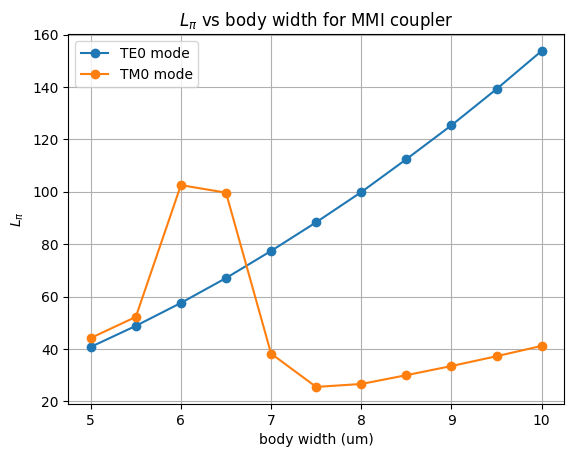

In [78]:
plt.title(r'$L_{\pi}$ vs body width for MMI coupler')
plt.plot(mmi_body_w_array, L_pi_TE_gap, 'o-', label='TE0 mode')
plt.plot(mmi_body_w_array, L_pi_TM_gap, 'o-', label='TM0 mode')
plt.xlabel('body width (um)')
plt.ylabel(r'$L_{\pi}$')
plt.grid()
plt.legend()